# Step 6. Aggregate private cluster results into PUBLIC, non-identifying outputs.

DHS forbids sharing cluster GPS points, so everything published is aggregated:
  * hexagons (H3 resolution 4, ~23 km edge, ~1,770 km2), hidden if < 3 clusters
  * admin-1 regions, hidden if < 5 clusters
  * open raster layers (MAP malaria, CHIRPS rainfall) as map images

Output (data/public/): hexes.geojson, regions.geojson, profiles_by_country.csv,
                       raster_*.png + raster_bounds.json, sample_summary.json

*Run on the author's computer. The DHS data are private, so the outputs shown here are summaries only (no cluster locations or survey records).*

In [1]:
import json
import h3
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import xarray as xr
import matplotlib
import matplotlib.image
from matplotlib import cm, colors
from shapely.geometry import Polygon
from config import PRIVATE, PUBLIC, MAP_DIR, CHIRPS_MONTHLY, AFRICA_BBOX

In [2]:
H3_RES, MIN_HEX, MIN_REGION = 4, 3, 5
cl = pd.read_parquet(PRIVATE / "clusters_final.parquet")
allc = pd.read_parquet(PRIVATE / "clusters_profiles.parquet")      # includes clusters w/o all model features
allc = allc.merge(cl[["idhspsu", "pred_rf", "resid_rf", "abs_err_rf"]], on="idhspsu", how="left")
n_prof = allc.profile.max()

In [3]:
def summarise(g):
    out = g.agg(n_clusters=("idhspsu", "size"), n_children=("n_children", "sum"),
                anemia_pct=("anemia_pct", "mean"), modsev_anemia_pct=("modsev_anemia_pct", "mean"),
                od_pct=("od_pct", "mean"), pfpr=("pfpr", "mean"),
                rain_3mo_z=("rain_3mo_z", "mean"), rain_annual_mm=("rain_annual_mm", "mean"),
                wealth=("wealth", "mean"), mom_secondary_pct=("mom_secondary_pct", "mean"),
                urban_pct=("urban", "mean"), in_hotspot_pct=("in_hotspot", "mean"),
                pred_anemia_pct=("pred_rf", "mean"), resid=("resid_rf", "mean"), abs_err=("abs_err_rf", "mean"),
                year_min=("int_year", "min"), year_max=("int_year", "max"),
                hot_25=("hot_25", "mean"), hot_50=("hot_50", "mean"), hot_75=("hot_75", "mean"),
                hot_100=("hot_100", "mean"),
                country=("country", lambda s: s.mode().iat[0]))
    for e in (25, 50, 75, 100):
        out[f"hot_{e}"] *= 100
    out["urban_pct"] *= 100
    out["in_hotspot_pct"] *= 100
    shares = pd.crosstab(g.obj[g.keys] if isinstance(g.keys, str) else g.obj[g.keys[0]],
                         g.obj["profile"], normalize="index") * 100
    shares = shares.reindex(columns=range(1, n_prof + 1), fill_value=0)
    shares.columns = [f"profile{p}_pct" for p in shares.columns]
    out = out.join(shares)
    out["profile"] = shares.to_numpy().argmax(axis=1) + 1          # most common profile
    names = allc.drop_duplicates("profile").set_index("profile").profile_name
    out["profile_name"] = out.profile.map(names)
    # dominant DBSCAN hotspot id (0 = none)
    hs = g.obj[g.obj.hotspot >= 0].groupby(g.keys).hotspot.agg(lambda s: s.mode().iat[0] + 1)
    out["hotspot_id"] = hs.reindex(out.index).fillna(0).astype(int)
    return out

## Hexagons

In [4]:
allc["hex"] = [h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(allc.lat, allc.lon)]
hx = summarise(allc.groupby("hex"))
hx = hx[hx.n_clusters >= MIN_HEX].reset_index()
hx["geometry"] = [Polygon([(lo, la) for la, lo in h3.cell_to_boundary(h)]) for h in hx.hex]
hx = gpd.GeoDataFrame(hx, crs="EPSG:4326").round(2)
hx["hex"] = range(1, len(hx) + 1)                                   # drop the real H3 id
hx.to_file(PUBLIC / "hexes.geojson", driver="GeoJSON")
print(f"Hexes: {len(hx):,} shown (>= {MIN_HEX} clusters), covering {hx.n_clusters.sum():,} of {len(allc):,} clusters")

Hexes: 2,037 shown (>= 3 clusters), covering 19,669 of 22,097 clusters


## Admin-1 regions

In [5]:
adm = gpd.read_file(PUBLIC / "admin1.geojson")
pts = gpd.GeoDataFrame(allc, geometry=gpd.points_from_xy(allc.lon, allc.lat), crs="EPSG:4326")
pts = gpd.sjoin(pts, adm[["region_id", "geometry"]], how="left", predicate="within")
# clusters falling just outside a polygon (coast, displacement) -> nearest region
miss = pts.region_id.isna()
if miss.any():
    near = gpd.sjoin_nearest(pts.loc[miss, ["geometry"]].to_crs(3857),
                             adm[["region_id", "geometry"]].to_crs(3857), how="left")
    pts.loc[miss, "region_id"] = near.groupby(level=0).region_id.first()
pts = pd.DataFrame(pts.drop(columns=["geometry", "index_right"]))
rg = summarise(pts.groupby("region_id")).drop(columns="country")
rg = rg[rg.n_clusters >= MIN_REGION]
regions = adm.merge(rg.reset_index(), on="region_id", how="left").round(2)
regions.to_file(PUBLIC / "regions.geojson", driver="GeoJSON")
print(f"Regions: {rg.shape[0]} of {len(adm)} with >= {MIN_REGION} clusters")

Regions: 325 of 334 with >= 5 clusters


## By country

In [6]:
bc = (pd.crosstab(allc.country, allc.profile_name, normalize="index") * 100).round(1)
bc["n_clusters"] = allc.groupby("country").size()
bc["anemia_pct"] = allc.groupby("country").anemia_pct.mean().round(1)
bc.reset_index().to_csv(PUBLIC / "profiles_by_country.csv", index=False)

## Open raster layers as images (for map overlays)

In [7]:
def to_png(arr, path, cmap, vmin, vmax):
    rgba = matplotlib.colormaps[cmap](colors.Normalize(vmin, vmax)(arr))
    rgba[..., 3] = np.where(np.isnan(arr), 0, 0.75)
    matplotlib.image.imsave(path, rgba)

In [8]:
bounds = {}
for yr in (2005, 2020):
    with rasterio.open(MAP_DIR / f"PfPR_2-10_Africa_{yr}.tif") as src:
        a = src.read(1).astype("float32")
        a[a < 0] = np.nan
        a = a[::2, ::2] * 100                                       # ~10 km, enough for a web map
        to_png(a, PUBLIC / f"raster_malaria_{yr}.png", "YlOrRd", 0, 70)
        b = src.bounds
        bounds[f"malaria_{yr}"] = [[b.bottom, b.left], [b.top, b.right]]

In [9]:
lon0, lat0, lon1, lat1 = AFRICA_BBOX
ann = []
for y in range(1981, 2011):
    da = xr.open_dataset(CHIRPS_MONTHLY / f"CHIRPS_monthly_{y}.nc")["precip"]
    ann.append(da.sel(longitude=slice(lon0, lon1), latitude=slice(lat1, lat0))[:, ::4, ::4].sum("time").values)
ann = np.mean(ann, axis=0)
ann[ann <= 0] = np.nan
to_png(ann, PUBLIC / "raster_rain_annual.png", "YlGnBu", 0, 2500)
bounds["rain_annual"] = [[lat0, lon0], [lat1, lon1]]
json.dump(bounds, open(PUBLIC / "raster_bounds.json", "w"))

## Headline numbers

In [10]:
flow = pd.read_csv(PRIVATE / "sample_flow.csv")
summary = {"children": int(allc.n_children.sum()), "clusters": len(allc),
           "countries": int(allc.country.nunique()), "surveys": int(allc["sample"].nunique()),
           "year_min": int(allc.int_year.min()), "year_max": int(allc.int_year.max()),
           "anemia_pct": round(float(allc.anemia_pct.mean()), 1),
           "hex_shown": len(hx), "regions_shown": int(rg.shape[0]),
           "sample_flow": flow.to_dict(orient="records")}
json.dump(summary, open(PUBLIC / "sample_summary.json", "w"), indent=2)
print(json.dumps({k: v for k, v in summary.items() if k != "sample_flow"}))

{"children": 236822, "clusters": 22097, "countries": 28, "surveys": 68, "year_min": 2000, "year_max": 2021, "anemia_pct": 63.5, "hex_shown": 2037, "regions_shown": 325}


## What gets published: hexagons

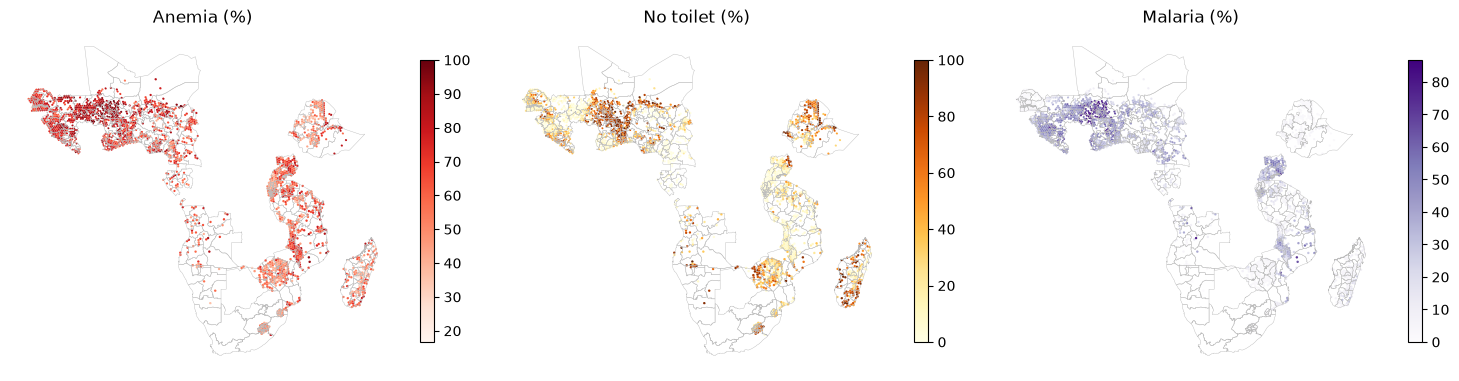

In [11]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, cmap, title) in zip(axes, [("anemia_pct", "Reds", "Anemia (%)"),
                                         ("od_pct", "YlOrBr", "No toilet (%)"),
                                         ("pfpr", "Purples", "Malaria (%)")]):
    adm.boundary.plot(ax=ax, color="#bbb", lw=0.3)
    hx.plot(col, ax=ax, cmap=cmap, legend=True, legend_kwds={"shrink": 0.6})
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout(); plt.show()